#  Theory of Machine Learning Loss Functions & Key Components

This notebook provides a detailed theoretical overview of key loss functions and activation mechanisms used in machine learning classification tasks:
1. **The Sigmoid Function** (Activation)
2. **Perceptron Loss Function**
3. **Hinge Loss**
4. **Binary Cross Entropy (Log Loss)**

## 1. The Sigmoid Function

The **Sigmoid function** (specifically the logistic sigmoid) is a mathematical activation function used to map any real-valued number into a probability value between 0 and 1.

### Mathematical Formulation
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Where:
- $z$ is the input (typically the log-odds or raw score $w^Tx + b$ outputted by a linear layer).
- $e$ is Euler's number.

### Properties
- **Range**: $(0, 1)$. This makes it ideal for binary classification where the output is interpreted as the probability $P(y=1|x)$.
- **Symmetric**: $\sigma(-z) = 1 - \sigma(z)$.
- **Derivative**: $\sigma'(z) = \sigma(z)(1 - \sigma(z))$. This simple derivative makes it computationally efficient during backpropagation.
- **Vanish Gradient Problem**: For very large positive or negative values of $z$, the curve becomes extremely flat, meaning the gradient $\sigma'(z)$ approaches 0. This can stall learning during neural network training.

## 2. Perceptron Loss Function

The **Perceptron Loss** is used in the classical Perceptron algorithm for binary classification where targets are typically encoded as $y \in \{-1, +1\}$.

### Mathematical Formulation
Given a prediction score $f(x) = w^Tx + b$, the Perceptron loss for a single sample is:

$$\mathcal{L}_{Perceptron}(y, f(x)) = \max(0, -y \cdot f(x))$$

### Explanation
- **Correct Classification**: If the sign of $f(x)$ matches $y$ (i.e., $y \cdot f(x) > 0$), the product is positive, $-y \cdot f(x)$ is negative, and the loss evaluates to $\max(0, \text{negative}) = 0$. Thus, there is no penalty for correctly classified points.
- **Incorrect Classification**: If the sign of $f(x)$ is different from $y$ (i.e., $y \cdot f(x) < 0$), the point is misclassified. The loss becomes positive and scales linearly with the distance from the decision boundary: $-y \cdot f(x)$.

## 3. Hinge Loss

**Hinge Loss** is primarily used in Support Vector Machines (SVMs). It extends the perceptron loss by introducing a **margin of safety** (typically set to 1).

### Mathematical Formulation
With targets labeled as $y \in \{-1, +1\}$:

$$\mathcal{L}_{Hinge}(y, f(x)) = \max(0, 1 - y \cdot f(x))$$

### Explanation
- **Incorrect Classifications**: If $y \cdot f(x) < 0$, the loss is strictly greater than 1 and increases linearly with distance.
- **Correct but Close Classifications (Within Margin)**: If $0 \le y \cdot f(x) < 1$, the prediction has the correct sign, but is too close to the decision boundary. The loss is non-zero ($1 - y \cdot f(x)$).
- **Correct and Confident Classifications**: Only when $y \cdot f(x) \ge 1$ (the prediction is correct and lies outside the margin boundary) does the loss become exactly 0.

This forces the decision boundary to maximize the separation margin between classes.

## 4. Binary Cross Entropy (BCE)

**Binary Cross Entropy** (also known as Log Loss) is the standard loss function used for binary classification when outputs are interpreted as probabilities, typically in Logistic Regression and Neural Networks.

### Mathematical Formulation
For labels $y \in \{0, 1\}$ and predicted probability $\hat{y} = \sigma(f(x)) \in [0, 1]$:

$$\mathcal{L}_{BCE}(y, \hat{y}) = - \left[ y \log(\hat{y}) + (1 - y) \log(1 - \hat{y}) \right]$$

### Explanation
- **If True Label $y = 1$**: The right-hand term $(1-y)$ disappears. The loss is $-\log(\hat{y})$. As predicted probability $\hat{y} \to 1$, loss $\to 0$. As $\hat{y} \to 0$, loss $\to \infty$.
- **If True Label $y = 0$**: The left-hand term disappears. The loss is $-\log(1 - \hat{y})$. As predicted probability $\hat{y} \to 0$, loss $\to 0$. As $\hat{y} \to 1$, loss $\to \infty$.

BCE heavily penalizes confident but incorrect predictions using the logarithmic scaling.

## 5. Visual Comparison of Loss Functions

To build a deeper intuitive understanding, we can plot these loss functions together.

We will plot the loss values against the **margin** (or decision score) $z = y \cdot f(x)$:
- When $z > 0$, the classification is correct.
- When $z < 0$, the classification is incorrect.
- **Zero-One Loss** (the classification error rate: 1 if incorrect, 0 if correct).
- **Perceptron Loss**: $\max(0, -z)$.
- **Hinge Loss**: $\max(0, 1 - z)$.
- **Binary Cross Entropy (Log Loss)**: $\log_2(1 + e^{-z})$ (scaled for normalized comparison on the margin).

# Code

In [4]:
from sklearn.datasets import make_classification
import numpy as np
X, y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=15)

In [7]:
X.shape

(100, 2)

In [8]:
y.shape

(100,)

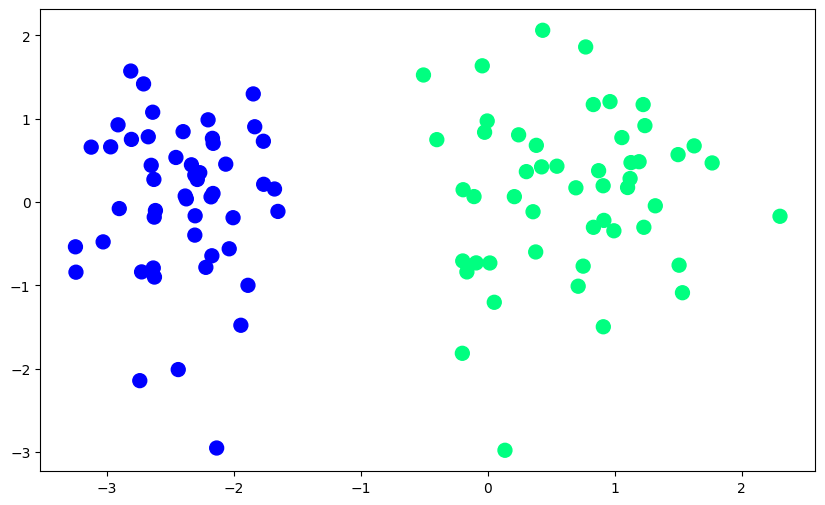

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [11]:
def perceptron(X,y):

    w1=w2=b=1
    lr = 0.1

    for j in range(1000):

        for i in range(X.shape[0]):

            # check condition
            z = w1*X[i][0] + w2*X[i][1] + b

            if z*y[i] < 0:
                w1 = w1 + lr*y[i]*X[i][0]
                w2 = w2 + lr*y[i]*X[i][1]
                b = b + lr*y[i]

    return w1,w2,b

In [12]:
 w1,w2,b = perceptron(X,y)

In [13]:
b

np.float64(1.3000000000000003)

In [14]:
w1

np.float64(1.006638570722407)

In [15]:
w2

np.float64(0.22215119727529098)

In [16]:
m = -(w1/w2)
c = -(b/w2)

print(m,c)

-4.531321834268464 -5.851870329508209


(-3.0, 2.0)

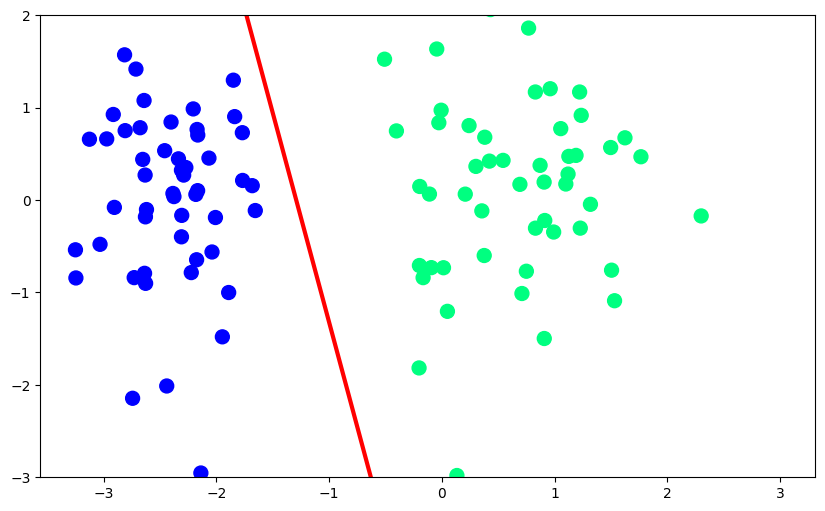

In [18]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + c

plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)


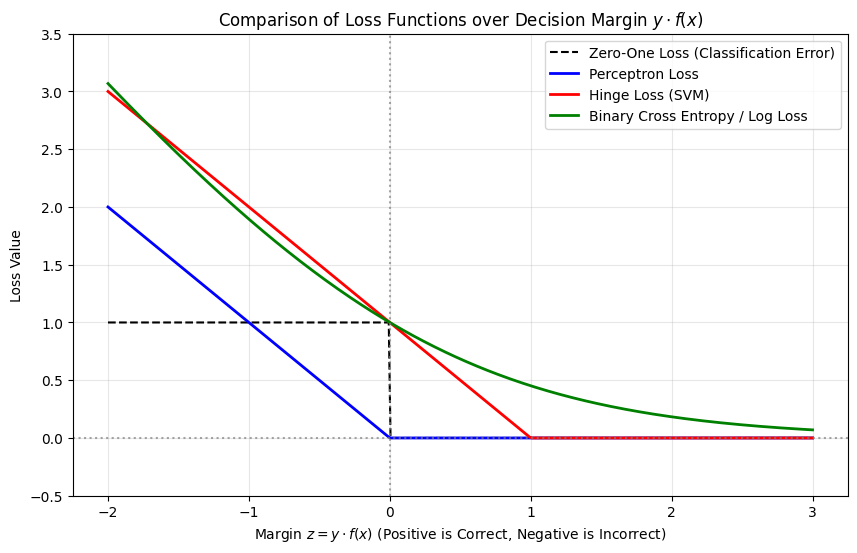

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a range of margin values (y * f(x))
z = np.linspace(-2.0, 3.0, 400)

# Define the loss functions
zero_one = np.where(z < 0, 1.0, 0.0)
perceptron = np.maximum(0, -z)
hinge = np.maximum(0, 1 - z)
log_loss = np.log2(1 + np.exp(-z)) # Binary Cross Entropy expressed in margin terms

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(z, zero_one, label='Zero-One Loss (Classification Error)', color='black', linestyle='--')
plt.plot(z, perceptron, label='Perceptron Loss', color='blue', linewidth=2)
plt.plot(z, hinge, label='Hinge Loss (SVM)', color='red', linewidth=2)
plt.plot(z, log_loss, label=r'Binary Cross Entropy / Log Loss', color='green', linewidth=2)

plt.axvline(x=0, color='gray', linestyle=':', alpha=0.7)
plt.axhline(y=0, color='gray', linestyle=':', alpha=0.7)

plt.title(r'Comparison of Loss Functions over Decision Margin $y \cdot f(x)$')
plt.xlabel(r'Margin $z = y \cdot f(x)$ (Positive is Correct, Negative is Incorrect)')
plt.ylabel('Loss Value')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.ylim(-0.5, 3.5)
plt.show()